In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim


In [ ]:
from sklearn.datasets import load_digits
import numpy as np

digits = load_digits()

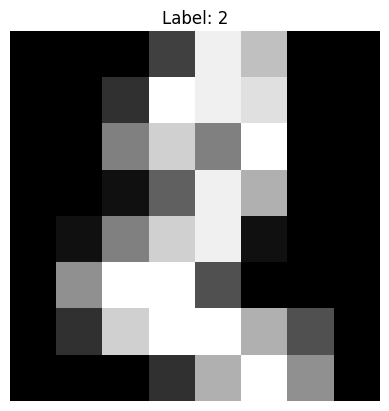

In [ ]:
import matplotlib.pyplot as plt

# Visualize the first digit (which is a 0)
plt.imshow(digits.images[2], cmap='gray')
plt.title(f"Label: {digits.target[2]}")
plt.axis('off')
plt.show()

In [ ]:
X = digits.data.astype("float32") / 16.0   # pixel values here range 0-16, scale to 0-1

X_train, X_test = X[:1500], X[1500:]

input_dim = X.shape[1]      # 64, the flattened 8x8 image

bottleneck_dim = 8          # the compressed representation size

In [ ]:

class Autoencoder(nn.Module):
    def __init__(self, input_dim, bottleneck_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, bottleneck_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [ ]:
autoencoder = Autoencoder(input_dim, bottleneck_dim)


In [ ]:
criterion = nn.MSELoss()


In [ ]:
optimizer = optim.Adam(
    autoencoder.parameters()
)

In [ ]:

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)



In [ ]:
epochs = 40
batch_size = 32

for epoch in range(epochs):

    autoencoder.train()

    # shuffle=True equivalent
    indices = torch.randperm(X_train_tensor.size(0))

    for start in range(0, X_train_tensor.size(0), batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch = X_train_tensor[batch_indices]

        optimizer.zero_grad() #clears the gradients left from the previous batch

        reconstructed = autoencoder(X_batch)

        loss = criterion(reconstructed, X_batch)

        loss.backward()  #calculates how each parameter affects the error

        optimizer.step() #changes the parameters using those gradients

# Validation
autoencoder.eval()

with torch.no_grad():    #tells pytorch not to build a gradient-tracking graph for this calculation
    reconstructed = autoencoder(X_test_tensor)
    validation_loss = criterion(reconstructed, X_test_tensor)

print("Final validation loss:", validation_loss.item())


Final validation loss: 0.04030942916870117


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import torch

labels = digits.target   # for this demo only, standing in for Nightwatch's volunteer-tagged labels

autoencoder.eval()
with torch.no_grad():
    # Convert X to a PyTorch tensor before passing to the encoder
    embeddings = autoencoder.encoder(torch.tensor(X, dtype=torch.float32)).numpy()

In [ ]:
emb_train, emb_test, y_train, y_test = train_test_split(
    embeddings, labels, test_size=0.3, random_state=42
)

clf = LogisticRegression(max_iter=1000)
clf.fit(emb_train, y_train)
preds = clf.predict(emb_test)

print("Accuracy using embeddings as features:", accuracy_score(y_test, preds))

Accuracy using embeddings as features: 0.737037037037037


In [ ]:
#transfer learning

In [ ]:

##### denoising ########

import numpy as np

X = digits.data.astype("float32") / 16.0
X_train, X_test = X[:1500], X[1500:]

noise_factor = 0.4
rng = np.random.default_rng(42)

X_train_noisy = X_train + noise_factor * rng.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_test_noisy = X_test + noise_factor * rng.normal(loc=0.0, scale=1.0, size=X_test.shape)

X_train_noisy = np.clip(X_train_noisy, 0.0, 1.0)
X_test_noisy = np.clip(X_test_noisy, 0.0, 1.0)

print("Clean training shape:", X_train.shape)
print("Noisy training shape:", X_train_noisy.shape)

Clean training shape: (1500, 64)
Noisy training shape: (1500, 64)


In [ ]:
denoiser_input = torch.tensor(X_train_noisy, dtype=torch.float32)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)

X_test_noisy_tensor = torch.tensor(X_test_noisy, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)


class DenoisingAutoencoder(nn.Module):
    def __init__(self, input_dim, bottleneck_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, bottleneck_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


denoising_autoencoder = DenoisingAutoencoder(input_dim, bottleneck_dim)

criterion = nn.MSELoss()
optimizer = optim.Adam(denoising_autoencoder.parameters())

# Note the target here is the CLEAN data, even though the input is noisy
epochs = 40
batch_size = 32

for epoch in range(epochs):

    denoising_autoencoder.train()

    # shuffle=True
    indices = torch.randperm(denoiser_input.size(0))

    for start in range(0, denoiser_input.size(0), batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch_noisy = denoiser_input[batch_indices]
        X_batch_clean = X_train_tensor[batch_indices]

        optimizer.zero_grad()

        denoised_output = denoising_autoencoder(X_batch_noisy)

        loss = criterion(denoised_output, X_batch_clean)

        loss.backward()

        optimizer.step()


denoising_autoencoder.eval()

with torch.no_grad():
    denoised_output = denoising_autoencoder(X_test_noisy_tensor)
    validation_loss = criterion(denoised_output, X_test_tensor)

print("Final validation loss:", validation_loss.item())



Final validation loss: 0.044172003865242004


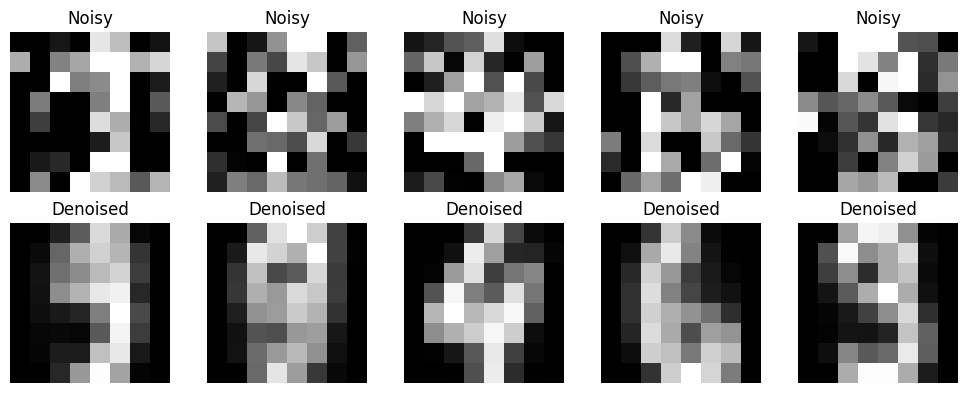

In [ ]:
# Visualization of original noisy input vs reconstructed output
import matplotlib.pyplot as plt

n_samples = 5
plt.figure(figsize=(10, 4))

for i in range(n_samples):
    # Display noisy images
    ax = plt.subplot(2, n_samples, i + 1)
    plt.imshow(X_test_noisy[i].reshape(8, 8), cmap='gray')
    plt.title("Noisy")
    plt.axis("off")

    # Display reconstructed images
    ax = plt.subplot(2, n_samples, i + 1 + n_samples)
    plt.imshow(denoised_output[i].numpy().reshape(8, 8), cmap='gray')
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()